## Step 1: Dataset Exploation

In [1]:
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import matplotlib.pyplot as plt


In [2]:

from pathlib import Path

data_dir = Path("../data/raw")

classes = sorted([
    folder.name
    for folder in data_dir.iterdir()
    if folder.is_dir()
])

print("Classes:", classes)
print("Number of classes:", len(classes))


Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Number of classes: 4


In [3]:
extensions = {".jpg", ".jpeg", ".png", ".bmp"}

for label in classes:
    folder = data_dir / label

    images = [
        file for file in folder.iterdir()
        if file.is_file()
        and file.suffix.lower() in extensions
    ]

    print(label, ":", len(images), "images")


glioma : 1621 images
meningioma : 1645 images
notumor : 2000 images
pituitary : 1757 images



## 1. Dataset Overview

The BrainScan AI dataset contains four classes:

- Glioma
- Meningioma
- No tumor
- Pituitary

The dataset contains 7,023 image files:

| Class | Number of images |
|---|---:|
| Glioma | 1,621 |
| Meningioma | 1,645 |
| No tumor | 2,000 |
| Pituitary | 1,757 |

The class distribution is reasonably balanced. We will investigate
the need for class weighting after evaluating model performance.


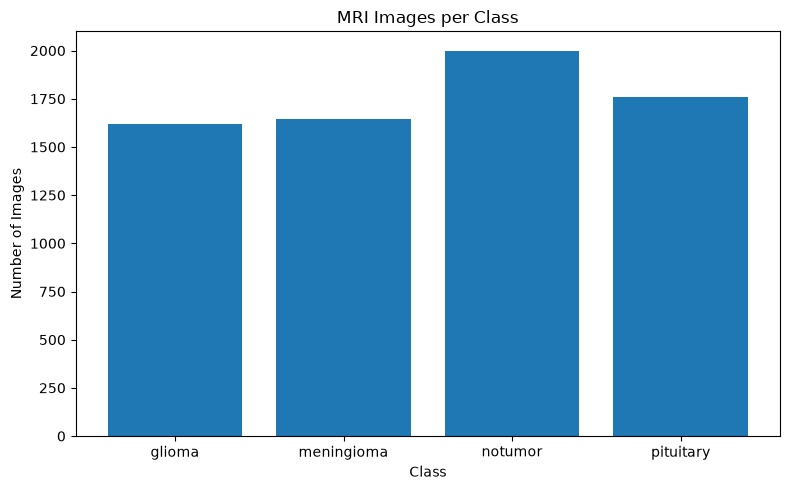

In [4]:
counts = {}

for label in classes:
    folder = data_dir / label

    images = [
        file for file in folder.iterdir()
        if file.is_file()
        and file.suffix.lower() in extensions
    ]

    counts[label] = len(images)

plt.figure(figsize=(8, 5))

plt.bar(classes, [counts[label] for label in classes])

plt.title("MRI Images per Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.show()



## 2. Understanding Image Representation

An image is represented numerically as an array of pixel values.

For an image with shape (height, width, channels):

- Height represents the number of pixel rows.
- Width represents the number of pixel columns.
- Channels represent the information stored for each pixel.

For example:

- (512, 512) represents a single-channel image.
- (512, 512, 3) represents a three-channel image.
- (512, 512, 3) does not mean that the image belongs to three classes.

The dataset samples currently use the uint8 data type.
We will inspect the pixel ranges and channel values to understand
how these images are encoded.


glioma | Shape: (512, 512, 3) | Data type: uint8
meningioma | Shape: (278, 440, 3) | Data type: uint8
notumor | Shape: (236, 236, 3) | Data type: uint8
pituitary | Shape: (512, 512, 3) | Data type: uint8


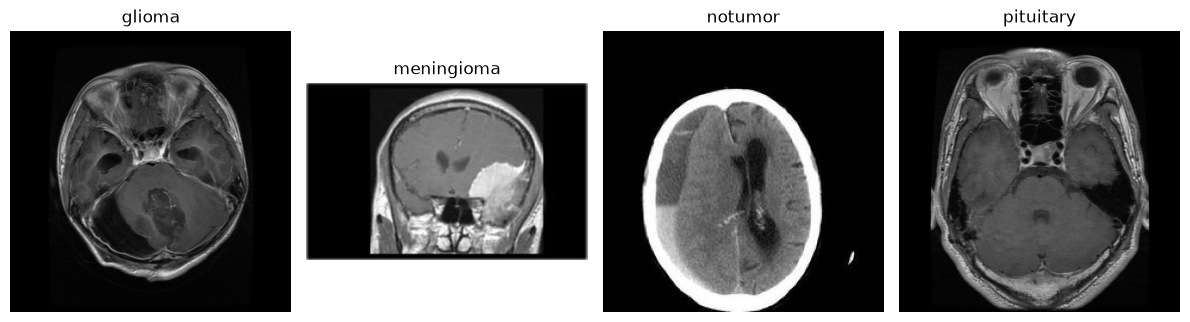

In [5]:
plt.figure(figsize=(12, 4))

for i, label in enumerate(classes):

    folder = data_dir / label

    image_files = [
        file for file in folder.iterdir()
        if file.is_file()
        and file.suffix.lower() in extensions
    ]

    image = cv2.imread(
        str(image_files[0]),
        cv2.IMREAD_UNCHANGED
    )

    print(
        label,
        "| Shape:", image.shape,
        "| Data type:", image.dtype
    )

    plt.subplot(1, 4, i + 1)

    if image.ndim == 2:
        plt.imshow(image, cmap="gray")
    else:
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))

    plt.title(label)
    plt.axis("off")

plt.tight_layout()
plt.show()



## 3. Initial Image Inspection

The sample images have different spatial dimensions.

For example, the glioma image has dimensions of 512 × 512,
while the meningioma image has dimensions of 278 × 440.

A CNN generally requires consistent input dimensions when images
are grouped into training batches.

We will therefore resize images to a fixed target size.

However, directly resizing every image to a square can distort
the anatomical proportions. We will investigate aspect-ratio-
preserving resizing with padding.

We will also distinguish spatial resizing from intensity
normalization:

- Resizing changes the image dimensions.
- Normalization changes the numerical scale of pixel values.

The original dataset will remain unchanged.
All preprocessing will be performed in Python.


In [6]:

for label in classes:

    folder = data_dir / label

    files = [
        file for file in folder.iterdir()
        if file.is_file()
        and file.suffix.lower() in extensions
    ]

    image = cv2.imread(
        str(files[0]),
        cv2.IMREAD_UNCHANGED
    )

    if image is None:
        print(label, "Image could not be read")
        continue

    print("\nClass:", label)
    print("Shape:", image.shape)
    print("Data type:", image.dtype)
    print("Minimum pixel value:", image.min())
    print("Maximum pixel value:", image.max())

    if image.ndim == 3 and image.shape[2] >= 3:

        channels = image[:, :, :3].astype(np.int16)

        max_difference = max(
            np.abs(channels[:, :, 0] - channels[:, :, 1]).max(),
            np.abs(channels[:, :, 1] - channels[:, :, 2]).max(),
            np.abs(channels[:, :, 0] - channels[:, :, 2]).max()
        )

        print("Maximum difference between channels:",
              max_difference)



Class: glioma
Shape: (512, 512, 3)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255
Maximum difference between channels: 0

Class: meningioma
Shape: (278, 440, 3)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255
Maximum difference between channels: 0

Class: notumor
Shape: (236, 236, 3)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255
Maximum difference between channels: 0

Class: pituitary
Shape: (512, 512, 3)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255
Maximum difference between channels: 0



## 4. Pixel Values and Channel Analysis

The inspected images use the uint8 data type, which represents
unsigned 8-bit integers in the range 0–255.

All inspected images have minimum pixel values of 0 and maximum
pixel values of 255.

The maximum difference between their three channels is zero.
This indicates that the inspected images contain identical values
across their channels and therefore have grayscale pixel content.

However, these findings currently apply only to the inspected
samples. We must examine the complete dataset before selecting
the final image representation.

### Preprocessing decisions

- Resizing will provide consistent spatial dimensions.
- Grayscale conversion may reduce redundant channel information.
- Pixel scaling will convert values from [0, 255] to [0, 1].
- These operations address different problems and must not
  be confused with one another.


In [7]:

from collections import Counter

records = []
shapes = Counter()
channel_types = Counter()
bad_files = []

for label in classes:

    folder = data_dir / label

    for path in folder.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in extensions:
            continue

        image = cv2.imread(
            str(path),
            cv2.IMREAD_UNCHANGED
        )

        if image is None:
            bad_files.append(path)
            continue

        records.append((path, label))
        shapes[image.shape] += 1

        if image.ndim == 2:
            channel_types["single-channel"] += 1

        elif image.ndim == 3 and image.shape[2] == 3:

            same_channels = (
                np.array_equal(image[:, :, 0], image[:, :, 1])
                and np.array_equal(image[:, :, 1], image[:, :, 2])
            )

            if same_channels:
                channel_types["three identical channels"] += 1
            else:
                channel_types["three different channels"] += 1

        else:
            channel_types["other formats"] += 1

print("Readable images:", len(records))
print("Unreadable images:", len(bad_files))

print("\nChannel analysis:")
for name, count in channel_types.items():
    print(name, ":", count)

print("\nMost common image shapes:")
for shape, count in shapes.most_common(10):
    print(shape, ":", count)


Readable images: 7023
Unreadable images: 0

Channel analysis:
three identical channels : 3800
single-channel : 3093
three different channels : 127
other formats : 3

Most common image shapes:
(512, 512) : 3049
(512, 512, 3) : 1693
(225, 225, 3) : 331
(236, 236, 3) : 81
(630, 630, 3) : 76
(251, 201, 3) : 58
(221, 228, 3) : 51
(217, 232, 3) : 50
(168, 300, 3) : 49
(198, 150, 3) : 44
